# Notebook 1 — Preprocess and Audit (every step visualised)

**What this notebook is for.** It takes the raw SutureBot2 folder and turns it into a clean, trustworthy, **stitch-level table** that the models can learn from. It does this in *small steps* — one step per cell — and shows you a picture of the data *after* each step, so nothing is a black box.

**Plain-English glossary (so the rest is easy to follow):**
- **Frame** — one still image (a screenshot) from the endoscope video, 960x540 pixels.
- **Mask** — a black-and-white image where white marks the wound area.
- **Bounding box (bbox)** — a rectangle drawn around a single stitch.
- **Stitch instance** — one stitch = one bounding box = one *row* in our table.
- **Episode** — one complete stitching attempt, made of many frames. Also called a **group**.
- **Batch** — a folder of episodes recorded by one operator (e.g. `fausto` or `jesse`).
- **Feature** — a number we compute to describe a stitch (its width, its distance to the wound, etc.).
- **Proxy score** — a 1-5 quality-like number we *calculate from geometry*, because there are no human ratings yet.

**How to read this notebook**
- Every step starts with a written explanation: **what the cell does, how it works, and what to look for in the output**.
- Every line of code has a short comment on the same line.
- Each step shows **numbers** (table shapes, counts) *and* a **figure**, so you can see the data change as we clean it.

> Important honesty note. SutureBot2 is a proof-of-concept **robotic, ex-vivo** dataset (pig tissue, two operators). It has **no** expert 1-5 stitch ratings. So this notebook makes a blank expert-rating sheet *and* a transparent **geometric-consistency proxy** target. The proxy is **not** clinical quality, and it must **never** be mixed with expert labels in one results table.

## Cell 1 — Set up the notebook

**What this cell does.** Gets the notebook ready: finds the project folder and imports all the shared code.

**How it works, step by step:**
1. `Path.cwd()` gets the folder the notebook is running in. The `while` loop then walks *up* the folder tree until it finds a folder containing `src/sutureqc` — that is the project root (`REPO`). This is why the notebook works no matter where it is launched from.
2. `sys.path.insert(...)` adds the `src` folder to Python's search path, so `import sutureqc` works.
3. It imports **pandas** (for tables), **matplotlib** (for drawing figures), and the `sutureqc` modules that contain the real preprocessing logic.
4. `show(fig)` is a small helper that shows a figure inline and then closes it, so memory does not fill up after dozens of figures.
5. It prints the repo path and the dataset path so you can confirm they are correct.

**What you should see:** two printed lines — your `repository` and `data root`. If these look wrong, fix the path before continuing.

In [1]:
import sys
from pathlib import Path

# Walk up from the current directory until we find the project root (the folder holding src/sutureqc).
REPO = Path.cwd()
while REPO != REPO.parent and not (REPO / "src" / "sutureqc").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

import json                     # read/write the audit report and proxy thresholds
import matplotlib.pyplot as plt  # inline figures
import pandas as pd              # every table in this notebook is a DataFrame
from IPython.display import Image, display

# Import the project package: all real preprocessing logic lives in src/sutureqc.
from sutureqc import audit, bbox, config, crops, geometry, labels_io, manifest, pipeline, points_io
from sutureqc import preprocess_viz as pv
from sutureqc import proxy, ratings, splits

pd.set_option("display.max_columns", 60)  # do not hide wide tables

# Helper that shows a live Figure inline and then closes it to free memory.
def show(fig):
    if fig is None:
        print("(figure not available)")
        return
    display(fig)
    plt.close(fig)

print("repository :", REPO)
print("data root  :", config.DATA_ROOT)


repository : D:\REU_new_dataset
data root  : D:\REU_new_dataset\SutureBot2


## Step 1 — Check the dataset folders exist

**What this cell does.** Before doing any work, it confirms that every folder the pipeline expects is actually present.

**How it works:**
- `verify_expected_folders()` looks for the data root, the `annotation_images` folder, the `masks` folder, the `stitch_bboxes` folder, the mask `manifest.csv`, and each batch folder. It returns a dictionary of `name -> True/False`.
- The `for` loop prints one line per check (`OK` or `MISSING`).
- The `assert` line is the important one: if any **required** (non-batch) folder is missing, it stops immediately with a clear error instead of failing later with a confusing message. The per-batch checks are informational only.

**What you should see:** a list of `OK` lines. If you see `MISSING` on a required folder, the dataset path is wrong.

In [2]:
# Ask the pipeline which expected folders are present (True/False per key).
checks = pipeline.verify_expected_folders()
for key, ok in checks.items():
    print(f"{'OK ' if ok else 'MISSING'}  {key}")
# Hard requirement: the non-batch folders must all exist, else abort.
assert all(v for k, v in checks.items() if not k.startswith("batch/")), "required dataset folders are missing"
print("\nAll required folders found.")

OK   data_root
OK   annotation_images
OK   masks
OK   stitch_bboxes
OK   manifest_csv
OK   batch/lerobot_fausto_batch_0
OK   batch/lerobot_fausto_batch_1
OK   batch/lerobot_jesse_batch_0
OK   batch/lerobot_jesse_batch_1
OK   batch/lerobot_jesse_batch_2
OK   batch/lerobot_wound_closure_dagger_01
OK   batch/lerobot_wound_closure_dagger_02
OK   batch/lerobot_wound_closure_dagger_03
OK   batch/lerobot_wound_closure_dagger_04
OK   batch/lerobot_wound_closure_dagger_05

All required folders found.


## Steps 2-3 — Load the author manifest and inventory every frame

**What this cell does.** Reads the dataset's own file list and builds a table covering **every** frame image (not just the annotated ones).

**How it works:**
1. `load_manifest()` reads `manifest.csv`. The authors wrote **their own absolute Windows paths** in it; this function rewrites each path to a local path by matching file names. It also parses each file name into `batch`, `episode`, `frame` and `group_id`.
2. `build_frame_inventory()` scans every frame `.png` and records: does this frame have a mask? does it have a bbox file? how many boxes does it contain, and how many are valid? Is it an **empty** box (a frame with *no* stitch — a useful "negative" example)?
3. It then prints the two table shapes and shows a picture summary.

**What you should see:** the printed shapes (about 853 frames), the first rows of the inventory table, and four small bar charts: frames per batch, how many have masks/boxes, empty vs non-empty frames, and how many boxes a frame usually has.

manifest rows  : (777, 8)
frame inventory: (853, 17)


,basename,frame_path,mask_path,bbox_path,batch,episode,frame,group_id,has_frame,has_mask,has_bbox,is_annotated,bbox_count,bbox_valid_count,bbox_invalid_count,bbox_invalid_reasons,is_empty_bbox
0,lerobot_fausto_batch_0__ep0__f0,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,lerobot_fausto_batch_0,0,0,lerobot_fausto_batch_0__ep0,True,True,True,True,0,0,0,,True
1,lerobot_fausto_batch_0__ep0__f10439,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,lerobot_fausto_batch_0,0,10439,lerobot_fausto_batch_0__ep0,True,True,True,True,0,0,0,,True
2,lerobot_fausto_batch_0__ep0__f5219,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,lerobot_fausto_batch_0,0,5219,lerobot_fausto_batch_0__ep0,True,True,True,True,1,1,0,,False
3,lerobot_fausto_batch_0__ep10__f0,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,lerobot_fausto_batch_0,10,0,lerobot_fausto_batch_0__ep10,True,True,True,True,0,0,0,,True
4,lerobot_fausto_batch_0__ep10__f2443,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,lerobot_fausto_batch_0,10,2443,lerobot_fausto_batch_0__ep10,True,True,True,True,1,1,0,,False


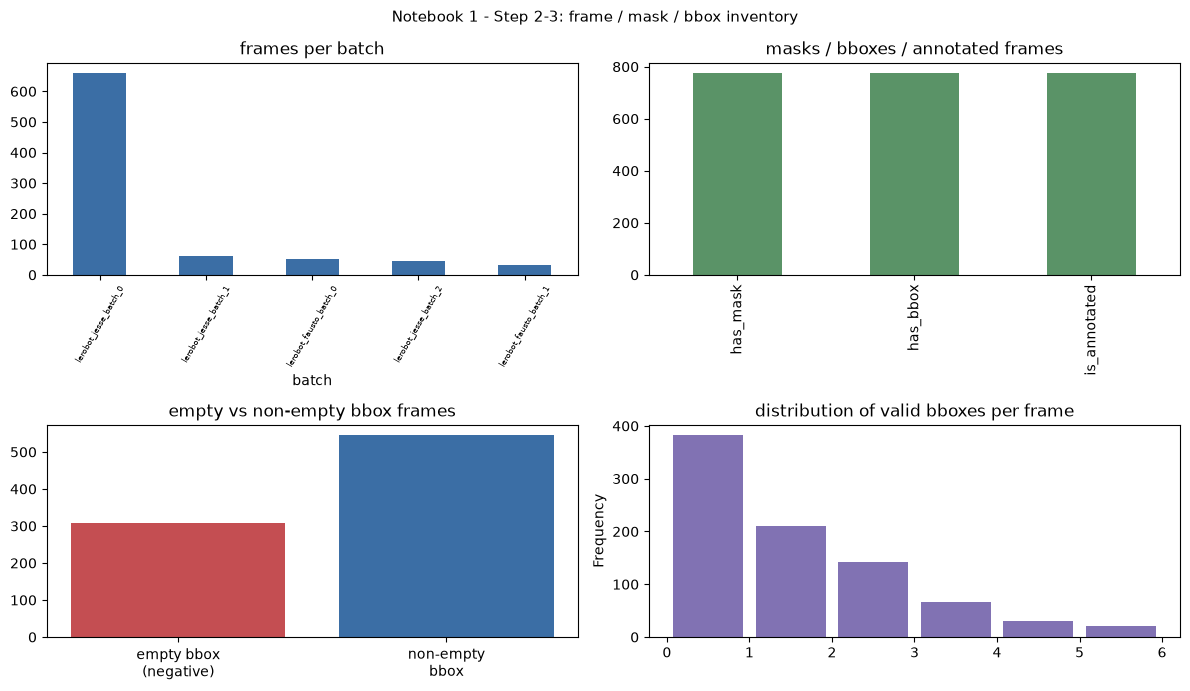

In [3]:
# Load the author manifest and rewrite its absolute paths to local paths.
base_manifest = manifest.load_manifest(config.DATA_ROOT)
# Build an inventory of EVERY frame, annotated or not (keeps empty negatives).
manifest_all = manifest.build_frame_inventory(config.DATA_ROOT, base_manifest)
print("manifest rows  :", base_manifest.shape)
print("frame inventory:", manifest_all.shape)
display(manifest_all.head())          # first rows of the inventory
show(pv.show_manifest_summary(manifest_all))  # visual summary of the inventory

## Steps 4-5 — Inspect and validate the stitch bounding boxes

**What this cell does.** Draws the raw boxes of one frame, and checks that every box is a *sensible* rectangle.

**How it works:**
- Each stitch-bbox file is a list of boxes written as `[x1, y1, x2, y2]` (top-left and bottom-right corners in pixels).
- `bbox.load_bboxes()` reads that list, and `show_bboxes()` draws each box on the actual frame with a number, so you can see what a human labelled.
- `validate_bbox()` (used while building the inventory) rejects impossible boxes — wrong number of values, NaN, zero/negative width or height — and remembers *why*. Those reasons are summarised by the `describe()` table.
- Empty-bbox frames are kept on purpose: they are valid "there is no stitch here" examples for a future detector, but they produce **no** scoring rows.

**What you should see:** one frame with red numbered boxes, plus a numeric summary (count, mean, min, max) of how many boxes exist and how many were valid vs invalid.

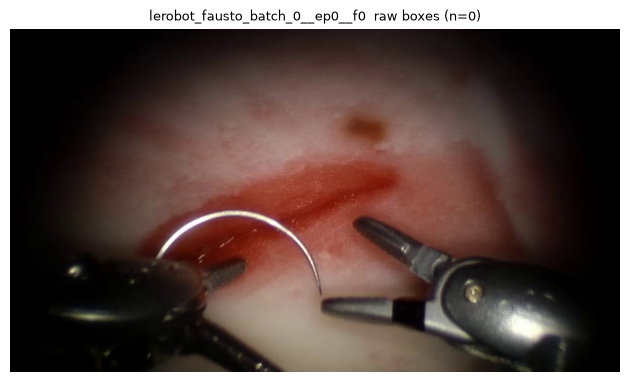

,bbox_count,bbox_valid_count,bbox_invalid_count
count,853.000000,853.000000,853.0
mean,1.077374,1.077374,0.0
std,1.275856,1.275856,0.0
min,0.000000,0.000000,0.0
25%,0.000000,0.000000,0.0
50%,1.000000,1.000000,0.0
75%,2.000000,2.000000,0.0
max,5.000000,5.000000,0.0


In [4]:
# Pick one annotated frame and draw its raw (unvalidated) boxes.
example = manifest_all[manifest_all["is_annotated"]].iloc[0]
raw_boxes = bbox.load_bboxes(example["bbox_path"])
show(pv.show_bboxes(example["frame_path"], raw_boxes,
                    title=f"{example['basename']}  raw boxes (n={len(raw_boxes)})"))
# Numeric summary of box counts and validation outcomes across all frames.
display(manifest_all[["bbox_count", "bbox_valid_count", "bbox_invalid_count"]].describe())

## Step 6 — Expand valid boxes into one row per stitch instance

**What this cell does.** Turns the list of boxes into the **stitch table** — the unit of work for everything downstream.

**How it works:**
- A single frame can contain several stitches. `stitch_instance_rows()` creates **one row per valid box**, giving each a unique `stitch_id` like `...__s1`, `...__s2`.
- Invalid boxes are skipped (they were already counted in the audit). Empty frames stay as negatives but add zero rows.
- Each row keeps the useful context: which frame, batch, episode and group the stitch belongs to, plus the box coordinates.

**What you should see:** the shape of the stitch table (about 919 rows), the first rows, and three bars: stitches per batch, how many stitches appear per frame, and the validation outcome.

stitch instances: (919, 15)


,stitch_id,basename,batch,episode,frame,group_id,stitch_index,x1,y1,x2,y2,bbox_valid_reason,frame_path,mask_path,bbox_path
0,lerobot_fausto_batch_0__ep0__f5219__s1,lerobot_fausto_batch_0__ep0__f5219,lerobot_fausto_batch_0,0,5219,lerobot_fausto_batch_0__ep0,1,290.149353,313.681824,386.928558,414.668823,ok,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...
1,lerobot_fausto_batch_0__ep10__f2443__s1,lerobot_fausto_batch_0__ep10__f2443,lerobot_fausto_batch_0,10,2443,lerobot_fausto_batch_0__ep10,1,436.019470,270.201294,459.863647,338.928558,ok,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...
2,lerobot_fausto_batch_0__ep10__f4885__s1,lerobot_fausto_batch_0__ep10__f4885,lerobot_fausto_batch_0,10,4885,lerobot_fausto_batch_0__ep10,1,429.006500,291.240265,460.564941,355.058441,ok,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...
3,lerobot_fausto_batch_0__ep10__f7328__s1,lerobot_fausto_batch_0__ep10__f7328,lerobot_fausto_batch_0,10,7328,lerobot_fausto_batch_0__ep10,1,432.513000,264.590912,473.188324,337.525970,ok,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...
4,lerobot_fausto_batch_0__ep10__f7328__s2,lerobot_fausto_batch_0__ep10__f7328,lerobot_fausto_batch_0,10,7328,lerobot_fausto_batch_0__ep10,2,521.577942,327.006500,558.746765,392.928558,ok,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...,D:\REU_new_dataset\SutureBot2\annotation_image...


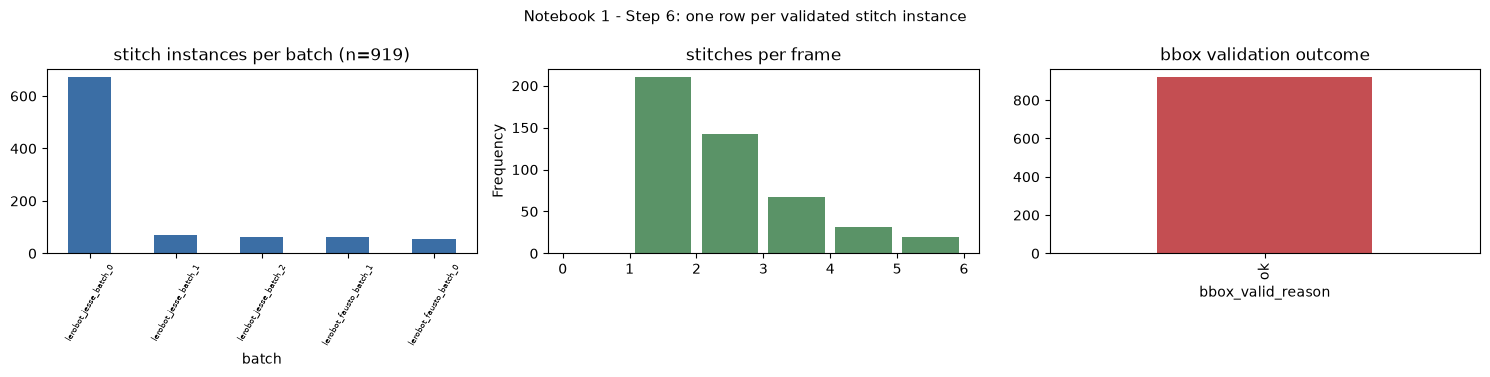

In [5]:
# One row per validated stitch box -> the stitch-level table.
stitch = manifest.stitch_instance_rows(manifest_all)
print("stitch instances:", stitch.shape)
display(stitch.head())
show(pv.show_stitch_instances(stitch))  # counts per batch, per frame, validation

## Step 7 — Attach the semantic action context

**What this cell does.** Adds, to each stitch, the *sub-task* the operator was performing at that moment.

**How it works:**
- `labels.jsonl` in each batch lists time ranges with a human-written label, e.g. "Pull the right gripper down...".
- `load_all_action_labels()` reads and combines those files across all batches.
- `annotate_action_context()` finds, for each stitch's frame number, which label range covers it, and copies across the label plus `action_progress` (0 = start of the sub-task, 1 = end). If no range matches, it uses `"unknown"`.

**What you should see:** a small table of stitch, label, start/end frame and progress; and a horizontal bar chart of the most common sub-task labels.

,stitch_id,action_label,action_start_frame,action_end_frame,action_progress
0,lerobot_fausto_batch_0__ep0__f5219__s1,Pull the right gripper down and the left gripp...,5139,5424,0.280702
1,lerobot_fausto_batch_0__ep10__f2443__s1,unknown,-1,-1,NaN
2,lerobot_fausto_batch_0__ep10__f4885__s1,unknown,-1,-1,NaN
3,lerobot_fausto_batch_0__ep10__f7328__s1,unknown,-1,-1,NaN
4,lerobot_fausto_batch_0__ep10__f7328__s2,unknown,-1,-1,NaN


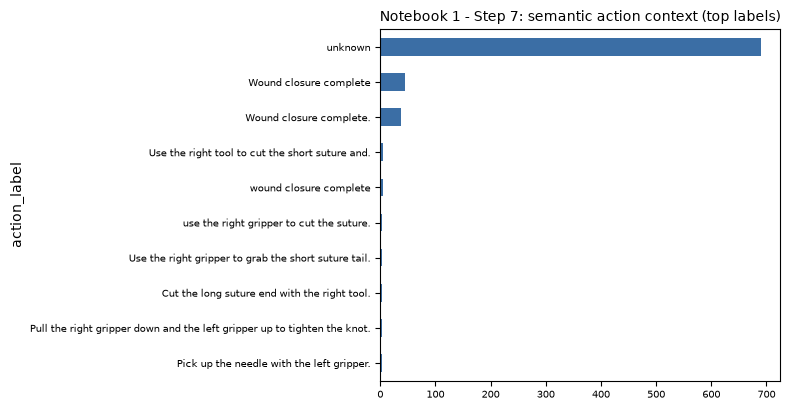

In [6]:
# Load every batch's action labels and attach the active label to each stitch.
action_labels = labels_io.load_all_action_labels(config.ALL_BATCHES, config.DATA_ROOT)
stitch = labels_io.annotate_action_context(stitch, action_labels)
display(stitch[["stitch_id", "action_label", "action_start_frame", "action_end_frame", "action_progress"]].head())
show(pv.show_action_labels(stitch))  # most common sub-task labels

## Step 8 — Compute the geometry features

**What this cell does.** For every stitch, it measures a set of **numbers that describe how the stitch sits relative to the wound**. These are the "explainable" part of the project.

**How it works:**
- It loads the needle insertion/exit annotations if present.
- `compute_geometry_features()` processes each frame once (reusing the loaded mask), and for each stitch computes:
  - box size: width, height, area, aspect ratio;
  - position: centre x/y, normalised to the image size;
  - wound-relative: distance from the stitch centre to the wound centre and to the wound **boundary**, how much the box overlaps the wound mask, whether the centre is inside the wound;
  - spacing: distance to the nearest other stitch, and how irregular the spacing is (`spacing_cv`);
  - needle info: insertion/exit length and alignment (when available).
- The overlay figure draws the mask, the box, both centres and the nearest-neighbour line for one stitch; the second figure shows the spread of each key feature.

**What you should see:** one annotated frame explaining the geometry, and a grid of histograms (one per feature).

geometry feature columns: 30


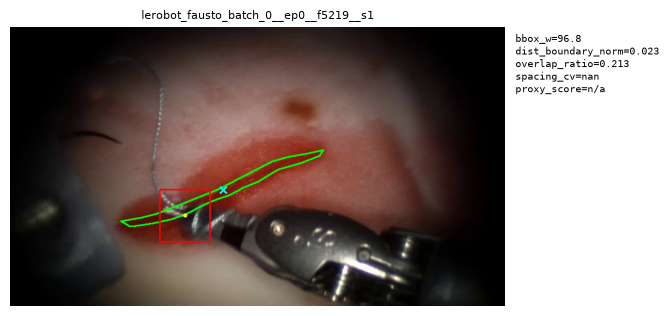

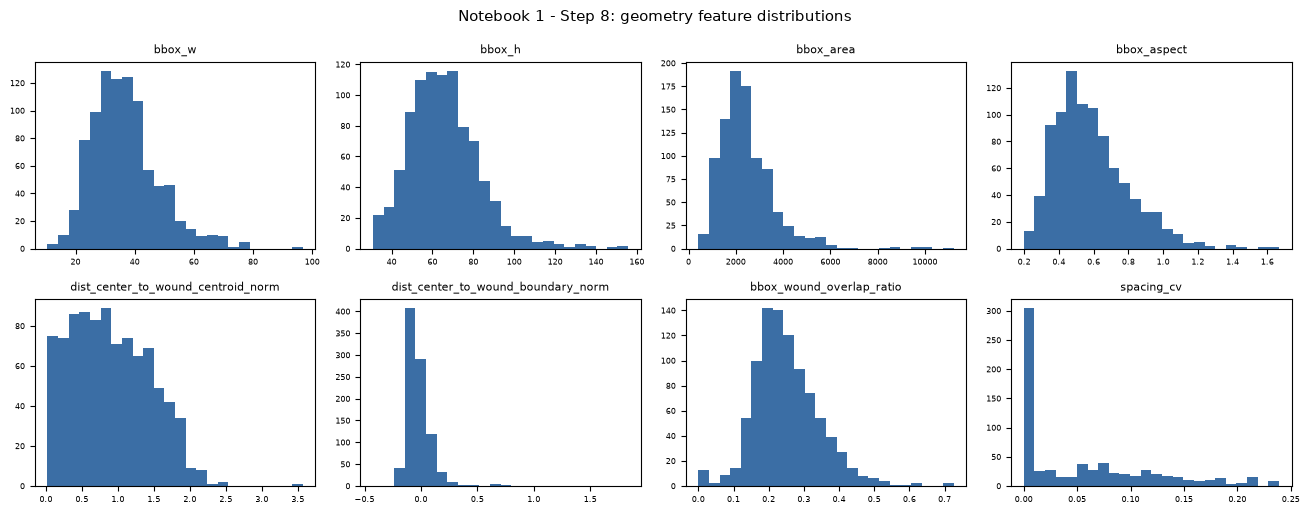

In [7]:
# Load needle insertion/exit annotations and compute all geometry features per stitch.
insertion_exit = points_io.load_all_insertion_exit(config.POINT_LABEL_BATCHES, config.DATA_ROOT)
features = geometry.compute_geometry_features(stitch, insertion_exit)
print("geometry feature columns:", len(geometry.GEOMETRY_FEATURE_COLUMNS))
# Overlay the measured geometry for the first stitch instance.
show(pv.show_geometry_overlay(features.iloc[0].to_dict()))
# Histograms of the most important geometric quantities.
show(pv.show_geometry_distributions(features))

## Step 9 — Generate the fixed padded stitch crops

**What this cell does.** Cuts a small picture around each stitch — the image the model will look at.

**How it works:**
- Rule: take the stitch box, add **20% padding** on all four sides, clip to the image edges, then resize to **224x224**. A fixed rule means every crop is produced the same way (reproducible).
- `show_crop_pipeline()` shows the rule in three panels: original box (red) + padded area (green) -> raw padded crop -> final 224x224 crop.
- `crops.generate_crops()` writes one file per stitch to `artifacts/crops/<stitch_id>.png` (and skips ones that already exist, so re-running is fast).

**What you should see:** the 3-panel crop rule, a grid of sample crops, and a count of how many crops exist.

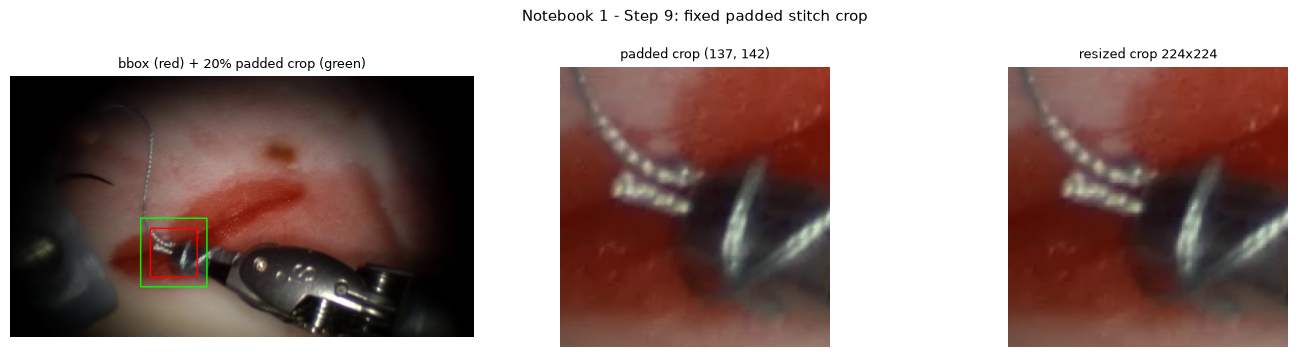

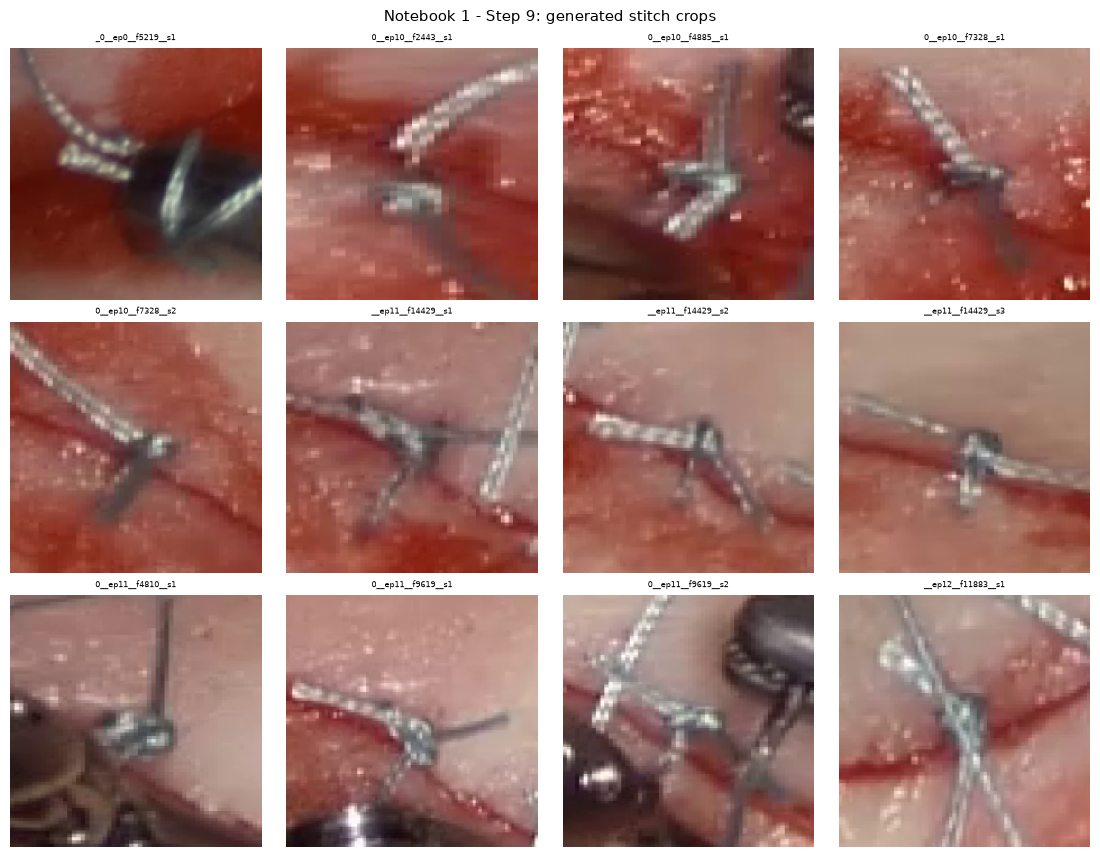

crops available: 919 / 919


In [8]:
# Show the crop rule on the first stitch: box -> padded box -> 224x224 crop.
first = stitch.iloc[0]
show(pv.show_crop_pipeline(first["frame_path"], [first["x1"], first["y1"], first["x2"], first["y2"]]))
# Generate (or reuse) all crops on disk, then show a sample grid.
crop_paths = crops.generate_crops(stitch)
show(pv.show_crops_grid(stitch))
print("crops available:", int(crop_paths["crop_exists"].sum()), "/", len(crop_paths))

## Step 10 — Build the blank expert-rating sheet (Milestone 0)

**What this cell does.** Creates the 1-5 rubric and an empty spreadsheet for human experts to score stitches.

**How it works:**
- The **rubric** (the written meaning of scores 1-5) lives in `config.RUBRIC`. It must be reviewed and approved by a clinician before real use — it is not yet a validated clinical scale.
- `build_expert_rating_template()` makes one row per stitch with empty columns `rater_1`, `rater_2`, `rater_3`, plus columns for consensus and timing.
- Once two or three experts fill it in, we can measure **inter-rater agreement** — how much humans agree — which becomes the human "ceiling" the model is compared against.

**What you should see:** the rubric table (score 1-5 with its meaning) and the first rows of the blank rating sheet.

In [9]:
# One row per stitch, blank rater columns for 3 experts.
rating_template = ratings.build_expert_rating_template(stitch, crop_paths, n_raters=3)
display(ratings.rubric_dataframe())   # the 1-5 rubric text
display(rating_template.head())       # the blank template

,score,operational_meaning
0,1,"Clearly poor: stitch is misplaced, badly misal..."
1,2,"Below acceptable: major irregularity, spacing,..."
2,3,Acceptable: wound approximation is usable but ...
3,4,Good: consistent placement and approximation w...
4,5,"Excellent: well-positioned, well-aligned, and ..."


,stitch_id,batch,episode,frame,stitch_index,x1,y1,x2,y2,crop_path,rater_1,rater_2,rater_3,consensus,n_scorable_raters,agreement,not_scorable,annotation_time_s,notes
0,lerobot_fausto_batch_0__ep0__f5219__s1,lerobot_fausto_batch_0,0,5219,1,290.149353,313.681824,386.928558,414.668823,D:\REU_new_dataset\artifacts\crops\lerobot_fau...,None,None,None,None,None,None,None,None,None
1,lerobot_fausto_batch_0__ep10__f2443__s1,lerobot_fausto_batch_0,10,2443,1,436.019470,270.201294,459.863647,338.928558,D:\REU_new_dataset\artifacts\crops\lerobot_fau...,None,None,None,None,None,None,None,None,None
2,lerobot_fausto_batch_0__ep10__f4885__s1,lerobot_fausto_batch_0,10,4885,1,429.006500,291.240265,460.564941,355.058441,D:\REU_new_dataset\artifacts\crops\lerobot_fau...,None,None,None,None,None,None,None,None,None
3,lerobot_fausto_batch_0__ep10__f7328__s1,lerobot_fausto_batch_0,10,7328,1,432.513000,264.590912,473.188324,337.525970,D:\REU_new_dataset\artifacts\crops\lerobot_fau...,None,None,None,None,None,None,None,None,None
4,lerobot_fausto_batch_0__ep10__f7328__s2,lerobot_fausto_batch_0,10,7328,2,521.577942,327.006500,558.746765,392.928558,D:\REU_new_dataset\artifacts\crops\lerobot_fau...,None,None,None,None,None,None,None,None,None


## Step 11 — Create the episode-grouped train / validation / test split

**What this cell does.** Splits the data into training, validation and test sets — **without cheating**.

**How it works:**
- The split key is the **episode** (`group_id`), never the individual frame. Frames from the same episode look almost identical, so if they were split across train and test the model could "memorise" and score unrealistically well.
- `assign_grouped_splits()` shuffles the list of episodes once (fixed random seed for reproducibility) and assigns roughly 60% / 20% / 20% to train / validation / test.
- `check_no_group_leakage()` proves that each episode appears in **exactly one** split. The `assert` stops the notebook if that is ever violated.

**What you should see:** the leakage report (should say `is_leaked: False`), and three bars: instances per split, how batches make up each split, and how many episode groups are in each split.

{'is_leaked': False, 'n_groups': 205, 'n_leaked_groups': 0, 'leaked_groups': [], 'n_instances_per_split': {'train': 561, 'test': 215, 'val': 143}}


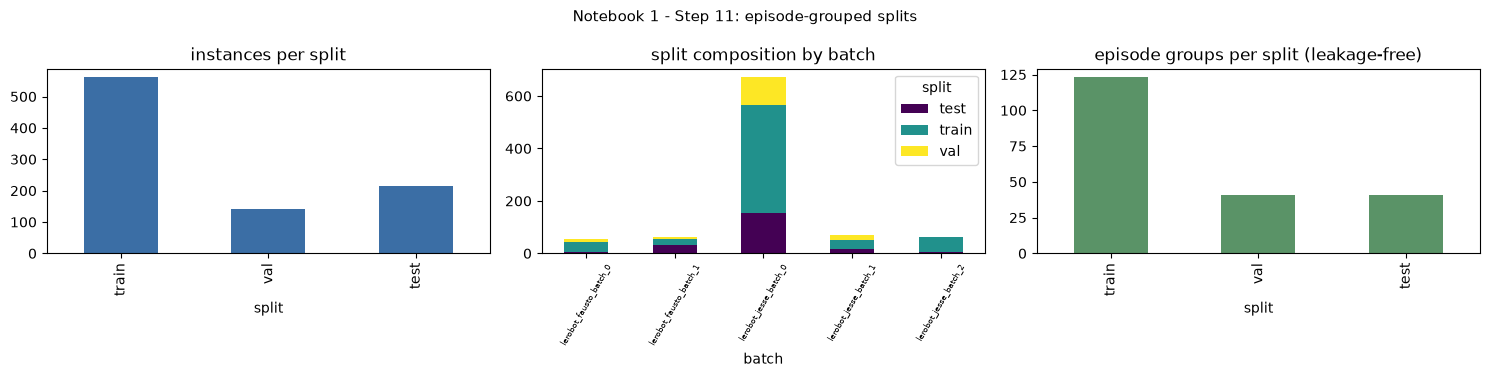

In [10]:
# Assign splits at episode level and verify there is no leakage.
splits_df = splits.assign_grouped_splits(features, group_col="group_id")
leakage = splits.check_no_group_leakage(splits_df)
features = features.assign(split=splits_df["split"].to_numpy())  # keep split on the feature table
print(leakage)
assert not leakage["is_leaked"], "episode leakage detected across splits"
show(pv.show_split_summary(features))  # sizes, batch composition and groups per split

## Step 12 — Build the geometric-consistency proxy target

**What this cell does.** Invents a 1-5 label from geometry, because no human labels exist yet.

**How it works:**
- Four sub-scores are computed from geometry and combined with fixed weights: **containment** (does the box overlap the wound?), **proximity** (is the stitch near/on the wound?), **spacing** (are stitches evenly spaced?) and **insertion/exit alignment**.
- The weighted average gives a continuous score between 0 and 1 (`proxy_score_continuous`).
- To turn it into 1-5, the code finds four **thresholds** using quantiles — but it fits those thresholds **only on the training rows**, then applies them everywhere. Fitting on all rows would leak information from test into train.
- The figure shows the continuous score with its threshold lines, and the resulting counts of scores 1-5.

**What you should see:** the histogram with red threshold lines, the ordinal bar chart, and the printed threshold values. **Remember: this is geometric consistency, not clinical quality.**

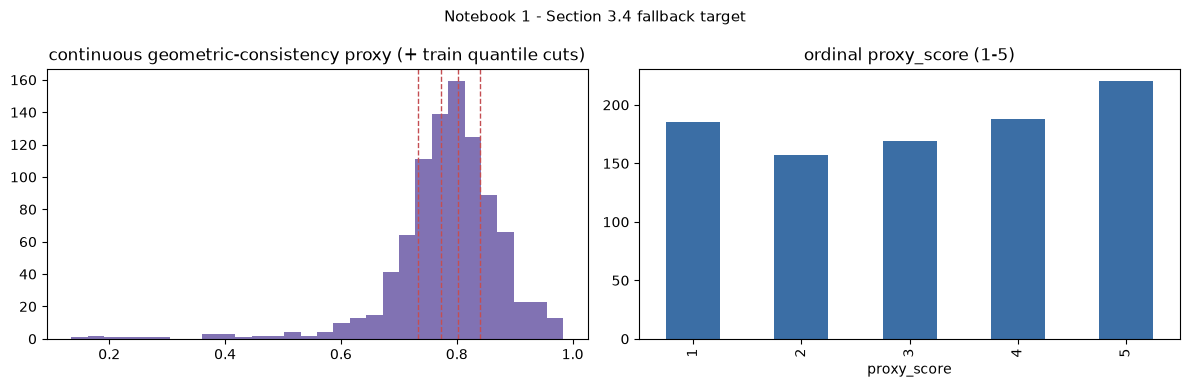

proxy thresholds: [0.7335, 0.7723, 0.8028, 0.8402]
proxy_score
1    185
2    157
3    169
4    188
5    220
Name: count, dtype: int64


In [11]:
# Fit proxy thresholds on the train split only, then label every stitch 1-5.
train_mask = (splits_df["split"] == "train").to_numpy()
features_with_proxy, proxy_thresholds = proxy.build_proxy_targets(features, train_mask)
show(pv.show_proxy_distribution(features_with_proxy, proxy_thresholds))
print("proxy thresholds:", [round(v, 4) for v in proxy_thresholds])
print(features_with_proxy["proxy_score"].value_counts().sort_index())

## Step 13 — Audit report and annotation overlay

**What this cell does.** Writes a quality report about the dataset and draws a picture to prove the annotations line up with the images.

**How it works:**
- `build_audit_report()` gathers counts, score distributions, duplicate IDs, missing masks, invalid-box reasons and the leakage check into one dictionary.
- `write_audit()` saves it as `artifacts/audit_report.json` so the dataset's cleanliness is documented and repeatable.
- `plot_sample_annotations()` draws sample frames with the wound mask (green) and stitch boxes (blue), then the cell displays that PNG.

**What you should see:** a few printed report sections (counts, score distribution, split sizes) and a grid image of frames with masks and boxes overlaid.

counts : {'frames_total': 853, 'frames_with_mask': 777, 'frames_with_bbox': 777, 'frames_annotated': 777, 'frames_empty_bbox_negative': 307, 'stitch_instances': 919, 'frames_missing_mask': 76}
proxy_score_distribution : {'5': 220, '4': 188, '1': 185, '3': 169, '2': 157}
split_sizes : {'train': 561, 'test': 215, 'val': 143}


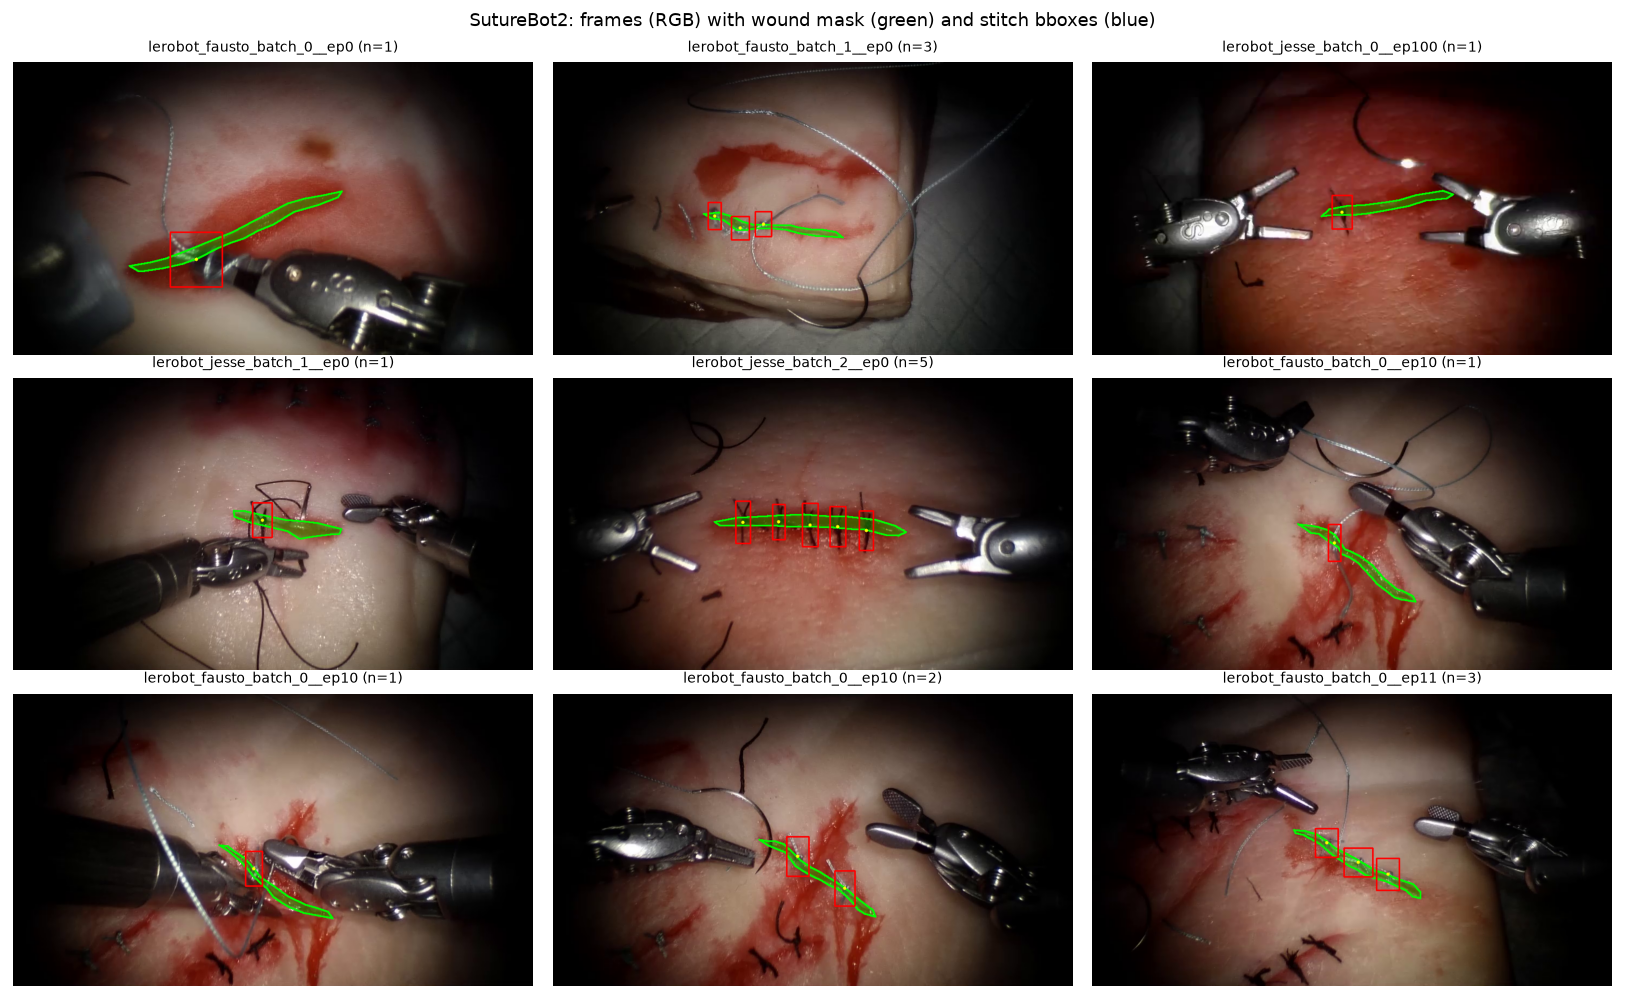

In [12]:
# Build and write the audit JSON, then draw the annotation overlay.
report = audit.build_audit_report(manifest_all, stitch, features_with_proxy, splits_df, proxy_thresholds)
report["leakage_check"] = leakage                     # store the leakage check inside the report
for key in ("counts", "proxy_score_distribution", "split_sizes"):
    print(key, ":", report.get(key))
audit.write_audit(report, config.AUDIT_REPORT_JSON)

# Draw the mask+box overlay on a sample of frames and display it.
audit.plot_sample_annotations(stitch, config.SAMPLE_ANNOTATIONS_PNG)
display(Image(str(config.SAMPLE_ANNOTATIONS_PNG)))

## Persist all artifacts

**What this cell does.** Builds everything *again* through the official single-call pipeline and writes it all to disk.

**How it works:**
- Steps 2-13 above built everything **in memory** so you could see each intermediate step. That is for teaching.
- This cell calls `pipeline.run_preprocess_pipeline()`, which runs the same steps in the same order and **writes every output file**, so the notebook does not duplicate the pipeline logic (the project rule is: notebooks explain, the package does the work).
- It then prints the shapes of the four key tables so you can confirm they match what you saw above.
- CSV files store paths **relative to the project root**; Notebooks 2-3 resolve them back to full paths automatically.

**What you should see:** the four table shapes (manifest 853, stitch 919, geometry 919, template 919) and the folders where artifacts and figures were written.

In [13]:
# Persist every Notebook-1 artifact by running the orchestrator once.
result = pipeline.run_preprocess_pipeline()
for name in ("manifest_all", "stitch_instances", "geometry_features", "expert_rating_template"):
    print(f"{name:24s}", result[name].shape)
print("proxy thresholds:", [round(v, 4) for v in result["proxy_thresholds"]])
print("\nartifacts written to:", config.ARTIFACTS_DIR)
print("figures written to  :", config.FIGURES_DIR)

manifest_all             (853, 17)
stitch_instances         (919, 19)
geometry_features        (919, 56)
expert_rating_template   (919, 19)
proxy thresholds: [0.7335, 0.7723, 0.8028, 0.8402]

artifacts written to: D:\REU_new_dataset\artifacts
figures written to  : D:\REU_new_dataset\figures


## Go / no-go gate (Milestone 1)

**What this cell does.** Acts as a safety gate: it refuses to let you train until the data is complete.

**How it works:**
- It checks four conditions for **every** stitch: does it have a crop image? a valid box? a known group? a target score?
- `gate.all(axis=1)` is `True` only when all four are true for a row; the cell counts those rows and asserts they equal the total.
- If anything is missing it throws an error, telling you to fix the pipeline before proceeding.

**What you should see:** `instances passing the gate: 919 / 919` and `GO: Milestone 1 artifacts are complete and leakage-free.`

In [14]:
# Verify every scored instance passes the four Milestone-1 conditions.
feats = result["geometry_features"]
crops_check = result["crops"].set_index("stitch_id")
gate = pd.DataFrame({
    "has_crop": feats["stitch_id"].map(crops_check["crop_exists"]).fillna(False).astype(bool),
    "has_bbox": feats[["x1", "y1", "x2", "y2"]].notna().all(axis=1),
    "has_group": feats["group_id"].notna(),
    "has_target": feats["proxy_score"].notna(),
})
print("instances passing the gate:", int(gate.all(axis=1).sum()), "/", len(gate))
assert gate.all(axis=1).all(), "not every scored instance satisfies the go/no-go gate"
print("GO: Milestone 1 artifacts are complete and leakage-free.")

instances passing the gate: 919 / 919
GO: Milestone 1 artifacts are complete and leakage-free.


## Artifacts written by this notebook

**What this cell does.** Lists every file the notebook created, so you know exactly what Notebook 2 will consume.

- `artifacts/manifest_all.csv` — every frame with mask/bbox flags (empty frames kept as negatives)
- `artifacts/stitch_instances.csv` — one row per validated stitch
- `artifacts/geometry_features.csv` — stitches + geometry features + proxy target + split
- `artifacts/expert_rating_template.csv` — blank expert rating sheet
- `artifacts/splits_grouped.csv` — episode-grouped split assignment (leakage-checked)
- `artifacts/proxy_thresholds.json` — the train-fold thresholds for the proxy target
- `artifacts/crops/` — the 224x224 stitch crops
- `artifacts/audit_report.json` — counts, distributions and quality checks
- `figures/sample_annotations.png` — frame + mask + bbox overlay

**Next up:** Notebook 2 uses these files to train and test the models.